<a href="https://colab.research.google.com/github/hgrigyan/deep_net_dev/blob/main/dnd26autumn_practice_week10_worksheet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Network Development, 2026 Autumn - Week 10 Practice - **Exercise sheet**

## Exercises

---

### Exercise 10.1: Handwritten digit classification with a CNN

Prepare grayscale images, train a small convolutional network, and inspect its
predictions on handwritten digits.


#### Provided setup

Load the digits dataset included with scikit-learn. Each image is an 8 × 8
grayscale digit. The setup creates fixed training, validation, and test splits,
scales pixel values to `[0, 1]`, and computes normalization statistics from the
training images. Run this cell unchanged.


In [1]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms.v2
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

transforms = torchvision.transforms

torch.set_num_threads(1)
torch.manual_seed(7)

digits = load_digits()
images = torch.tensor(digits.images, dtype=torch.float32).unsqueeze(1) / 16
labels = torch.tensor(digits.target, dtype=torch.long)

train_idx, remaining_idx = train_test_split(
    range(len(labels)), test_size=0.30, random_state=7, stratify=digits.target
)
val_idx, test_idx = train_test_split(
    remaining_idx, test_size=0.50, random_state=7, stratify=digits.target[remaining_idx]
)
x_train, y_train = images[train_idx], labels[train_idx]
x_val, y_val = images[val_idx], labels[val_idx]
x_test, y_test = images[test_idx], labels[test_idx]

channel_mean = [x_train.mean().item()]
channel_std = [x_train.std(unbiased=False).item()]

print('Classes:', digits.target_names.tolist())
for name, xs, ys in [('Training', x_train, y_train),
                     ('Validation', x_val, y_val), ('Test', x_test, y_test)]:
    print(f'{name}: images {tuple(xs.shape)}, labels {tuple(ys.shape)}')


Classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Training: images (1257, 1, 8, 8), labels (1257,)
Validation: images (270, 1, 8, 8), labels (270,)
Test: images (270, 1, 8, 8), labels (270,)


#### Task 1: Image transforms

Define `train_transform` with random rotation (up to 12°), translation (up to
12.5% per axis), Gaussian noise (standard deviation 0.04), and normalization.

Define `test_transform` for validation and test images using normalization
only. Use `channel_mean` and `channel_std` in both pipelines.


Task 1 passed!


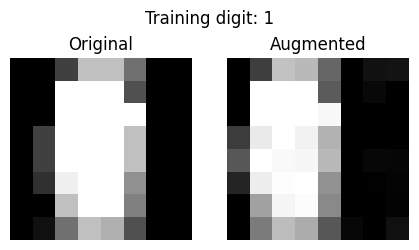

In [2]:
# TODO: define the training transforms
# SOLUTION 1 START
train_transform = transforms.v2.Compose([
    transforms.v2.RandomAffine(degrees = 12, translate = (0.125,0.125)),
    transforms.v2.GaussianNoise(sigma=0.04),
    transforms.v2.Normalize(mean = channel_mean, std = channel_std)
])
# SOLUTION 1 END

# TODO: define the validation/test transforms
# SOLUTION 2 START
test_transform = transforms.v2.Normalize(mean=channel_mean, std=channel_std)
# SOLUTION 2 END

preview = x_train[0]
augmented = train_transform(preview)
assert augmented.shape == preview.shape and augmented.dtype == torch.float32
assert torch.isfinite(augmented).all()
assert torch.allclose(test_transform(preview),
                      (preview - channel_mean[0]) / channel_std[0])
print('Task 1 passed!')

# Undo normalization for display.
fig, axes = plt.subplots(1, 2, figsize=(4.5, 2.5))
for ax, image, title in zip(
    axes,
    [preview, augmented * channel_std[0] + channel_mean[0]],
    ['Original', 'Augmented'],
):
    ax.imshow(image[0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')
fig.suptitle(f'Training digit: {y_train[0].item()}')
plt.tight_layout()
plt.show()


#### Task 2: Dataset and DataLoaders

Complete `DigitsDataset.__getitem__` so it applies the assigned transform to
the image when it is fetched. Return the transformed image and its unchanged
label.


In [3]:
class DigitsDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # TODO: transform the image and return it with its label
        # SOLUTION 3 START
        return self.transform(self.images[idx]), self.labels[idx]
        # SOLUTION 3 END

train_dataset = DigitsDataset(x_train, y_train, train_transform)
val_dataset = DigitsDataset(x_val, y_val, test_transform)
test_dataset = DigitsDataset(x_test, y_test, test_transform)

BATCH_SIZE = 64
dataloader_train = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
dataloader_val = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
dataloader_test = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

sample_x, sample_y = val_dataset[0]
assert torch.allclose(sample_x, test_transform(x_val[0]))
assert torch.equal(sample_y, y_val[0])
batch_xs, batch_ys = next(iter(dataloader_train))
assert batch_xs.shape == (BATCH_SIZE, 1, 8, 8) and batch_xs.dtype == torch.float32
assert batch_ys.shape == (BATCH_SIZE,) and batch_ys.dtype == torch.long
print('Batch shapes:', batch_xs.shape, batch_ys.shape)
print('Task 2 passed!')


Batch shapes: torch.Size([64, 1, 8, 8]) torch.Size([64])
Task 2 passed!


#### Task 3: Define a CNN and choose the loss

Implement `DigitCNN` using `nn.Sequential` in `self.network`. Use two blocks,
each with a 3 × 3 convolution (`padding=1`), ReLU, and 2 × 2 max pooling.
The first block has 8 output channels and the second has 16.

Flatten the final feature maps per image and use a linear layer to return
ten logits. Choose the appropriate loss function.


In [5]:
torch.manual_seed(7)

class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: define the network
        # SOLUTION 4 START
        self.network = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(2*2*16, 10)

        )
        # SOLUTION 4 END

    def forward(self, x):
        # TODO: compute the logits
        # SOLUTION 5 START
        return self.network(x)
        # SOLUTION 5 END

model = DigitCNN()

# TODO: choose the classification loss
# SOLUTION 6 START
loss_fn = nn.CrossEntropyLoss()
# SOLUTION 6 END

with torch.no_grad():
    example_logits = model(batch_xs[:4])
    example_loss = loss_fn(example_logits, batch_ys[:4])
assert example_logits.shape == (4, 10)
assert example_loss.ndim == 0 and torch.isfinite(example_loss)
print('Output shape:', example_logits.shape)
print('Task 3 passed!')


Output shape: torch.Size([4, 10])
Task 3 passed!


#### Task 4: Train the CNN

Run the training loop for 15 epochs. Inspect the training and
validation loss and accuracy curves.


In [6]:
# Training loop
n_epochs = 15
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
train_losses, val_losses = [], []
train_accuracy, val_accuracy = [], []

for epoch in range(n_epochs):
    model.train()
    train_batch_losses, train_correct = [], 0
    for xs, ys in dataloader_train:
        optimizer.zero_grad()
        logits = model(xs)
        loss = loss_fn(logits, ys)
        train_batch_losses.append(loss.detach())
        loss.backward()
        optimizer.step()
        train_correct += (logits.argmax(dim=1) == ys).sum().item()

    model.eval()
    val_batch_losses, val_correct = [], 0
    with torch.no_grad():
        for xs, ys in dataloader_val:
            logits = model(xs)
            loss = loss_fn(logits, ys)
            val_batch_losses.append(loss)
            val_correct += (logits.argmax(dim=1) == ys).sum().item()

    train_losses.append(torch.stack(train_batch_losses).mean().item())
    val_losses.append(torch.stack(val_batch_losses).mean().item())
    train_accuracy.append(train_correct / len(train_dataset))
    val_accuracy.append(val_correct / len(val_dataset))

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f'Epoch {epoch + 1:2d}: train loss {train_losses[-1]:.3f}, '
              f'val loss {val_losses[-1]:.3f}, val accuracy {val_accuracy[-1]:.3f}')
print('Training finished.')


Epoch  1: train loss 2.244, val loss 2.070, val accuracy 0.396
Epoch  5: train loss 1.129, val loss 0.687, val accuracy 0.819
Epoch 10: train loss 0.611, val loss 0.312, val accuracy 0.922
Epoch 15: train loss 0.461, val loss 0.240, val accuracy 0.933
Training finished.


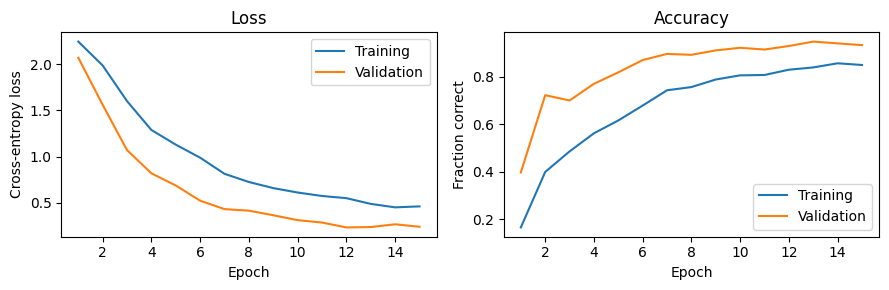

In [7]:
# Plotting the training and validation loss and accuracy curves
epochs = range(1, n_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, train_values, val_values, title, ylabel in [
    (axes[0], train_losses, val_losses, 'Loss', 'Cross-entropy loss'),
    (axes[1], train_accuracy, val_accuracy, 'Accuracy', 'Fraction correct'),
]:
    ax.plot(epochs, train_values, label='Training')
    ax.plot(epochs, val_values, label='Validation')
    ax.set(xlabel='Epoch', ylabel=ylabel, title=title)
    ax.legend()
plt.tight_layout()
plt.show()


#### Task 5: Inspect test predictions

Predict the digit classes for one test batch. Store the predicted class indices
in `test_predictions`. The provided grid shows six images with their true and
predicted classes.


First test batch accuracy: 0.953


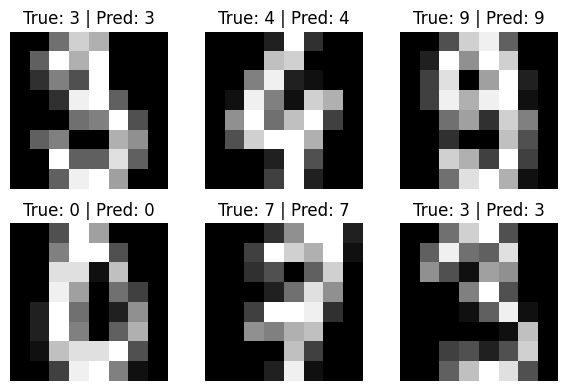

In [9]:
test_xs, test_ys = next(iter(dataloader_test))
model.eval()
with torch.no_grad():
    # TODO: compute the batch logits and convert them to class indices
    # SOLUTION 7 START
    test_logits = model(test_xs)
    test_predictions = test_logits.argmax(dim=1)
    # SOLUTION 7 END

assert test_predictions.shape == test_ys.shape and test_predictions.dtype == torch.long
assert torch.all((0 <= test_predictions) & (test_predictions < 10))
batch_accuracy = (test_predictions == test_ys).float().mean().item()
print(f'First test batch accuracy: {batch_accuracy:.3f}')

# Undo normalization for display
fig, axes = plt.subplots(2, 3, figsize=(6, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(test_xs[i, 0] * channel_std[0] + channel_mean[0],
              cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'True: {test_ys[i].item()} | Pred: {test_predictions[i].item()}')
    ax.axis('off')
plt.tight_layout()
plt.show()


#### Extra exercise: Visualize feature maps

Pass the first test digit through only the trained network's first convolutional
layer. Store the first four output channels, before ReLU or pooling, in
`feature_maps` with shape `(4, 8, 8)`. Use the provided plot to compare where
the filters respond.


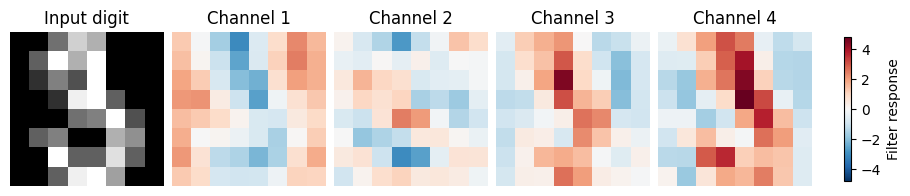

In [10]:
model.eval()
with torch.no_grad():
    # TODO: keep the batch axis at input and select four channels from the output
    # SOLUTION 8 START
    first_layer_output = model.network[0](test_xs[:1])
    feature_maps = first_layer_output[0, :4]
    # SOLUTION 8 END

assert feature_maps.shape == (4, 8, 8)
# Supplied: show signed responses on a common color scale
fig, axes = plt.subplots(1, 5, figsize=(9, 2.3), layout='constrained')
axes[0].imshow(test_xs[0, 0] * channel_std[0] + channel_mean[0],
               cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Input digit')
limit = max(feature_maps.abs().max().item(), 1e-6)
for i, ax in enumerate(axes[1:]):
    panel = ax.imshow(feature_maps[i], cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_title(f'Channel {i + 1}')
for ax in axes:
    ax.axis('off')
fig.colorbar(panel, ax=list(axes[1:]), shrink=0.65, label='Filter response')
plt.show()
